# **STEP 2, PART 2**
### ***Checking whether the model converges against LAB.***

The convergence study is repeated with the three Marasco+12 residuals (absolute, squared, relative) as was in the comparison test.

The convergence cubes were already generated from previous attempts, but feature a wide range of tested parameters. They were generated using parallel processes.

The LAB data itself provide the baseline through the sector **jackknife** of each residual (the data-side uncertainty), and the model-side Monte Carlo noise is measured from runs that differ only in the random seeds.

For each residual R (relative units, so that the three can be compared), we have
* **Noise** = std(R) / mean(R) over seeds at fixed n, and how it falls with n (expected ~ n^-1/2),
* **Data-side error** = jackknife standard error of R / R (what LAB allows us to know),
* **Convergence criterion** = noise well below the data-side error (here: below 1/10th of it),
* **Sensitivity** = relative change of R per km/s of `hv0`, from the `N` groups (hv0 = 60) and the `D` groups (hv0 = 65, same seeds with `N`): the 'signal' of a grid step; noise per evaluation expressed in km/s of `hv0 = noise / |sensitivity|`, with and without common random numbers,
* **Numerical settings** (`dx_phys`, azimuth lattice (`factor_phi_res`), kernel (on/off), `R_clump`, iterations `n_iter_add`) and the `dR` scan: paired shifts of R relative to the `n = N_REF` baseline, in units of the noise,
* **What dominates:** effective number of voxels and the share of the top 1% of voxels, per residual.

The convergence cubes are at the reference point `(hv0 = 60, alpha_hv = 0.2, f_ion = 1, alpha_conds = 6.3)`. The noise there is a first estimate and has to be rechecked at the best-fit region of whichever observable we adopt.

*Currently, comparison test produced no discernible plateau results with `B_CUT` or `L_CUT`. While we adopted them here now, they remain set to zero.*

### New in this version: three sets of residuals
`evaluate()` now computes three **sets** of the three residuals (keys in brackets):
* **base** (`R_abs`, `R_sq`, `R_rel`): the previous definition, all voxels, the relative residual softened by `REL_FLOOR`. Kept as the reference to the earlier convergence results.
* **Mrsc** (`R_abs_M`, `R_sq_M`, `R_rel_M`): Marasco's own C++ code (Li+23 repository). Only voxels where LAB or the model exceeds **0.04 K** count; relative residual `|D-M| / max(D, M)`.
* **Li** (`R_abs_L`, `R_sq_L`, `R_rel_L`): Li-style. The same selection at **`K_L` sigma** of LAB's noise (sigma from `sigma_contours`, step 2b), plus a penalty for model flux that lands in unselected voxels (abs and sq; it is not defined for the relative residual).

In all three the flux scale is the paper's (all compared voxels, $\cos(b)$ weighted).

In [1]:
import sys, re, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *

LAB_PATH = "../Displays/lab.fit.gz"
PRODUCTS = "lab_products.npz"           # written by background_remove.ipynb: the LAB cube to use and its sigma
GRID = Path("./grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("./conv")                   # the convergence-study cubes (tiers 1-4)
B_CUT = 0
L_CUT = 0
V_DEV = 35.0                            # km/s: |v_dev| below this is disc (Marasco+12: 35; the comparison test uses the same)
REL_FLOOR = 0.04                        # K: softening of the relative residual of the 'base' set
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

We prepare the LAB data. Here the masks are made and applied to LAB, but there is an option to apply a `B_CUT` and an `L_CUT`.

In [2]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

SIGMA_NUM = P.sigma_empty   # K: sigma of LAB's noise at 8 deg / 8 km/s on clean pixels
T_M = 0.04                  # K: threshold of Marasco's code (threshold_res)
K_L = 2.0                   # Li-style threshold in sigma (the NGC 2403 code: 2 rms)

RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    # all voxels, soft floor REL_FLOOR (the previous convergence study)
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    # Marasco's code: data > T or model > T
    "Li": dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
    # Li-style: the same at K_L sigma, with the penalty for model flux in blank voxels
}

cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)

OBS = list(cmp.keys)                    # every residual key: abs, sq, rel, abs_M, ..., rel_L.
SETS = list(cmp.sets)                   # base, Mrsc, Li
OBS3 = ("abs", "sq", "rel")             # the three residuals inside a set; key_of(set, obs) gives the key

print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data\n")

for n_, s_ in cmp.sets.items():
    print(f"Residual set {n_:5s}: {s_}")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: lab_background_correction.npz
Comparison grid: 62 channels x 41 b x 90 l; 163347 LAB voxels with data

Residual set base : {'kind': 'soft'}
Residual set Mrsc : {'kind': 'select', 'T': 0.04, 'rel': 'max', 'blanks': False}
Residual set Li   : {'kind': 'select', 'k': 2.0, 'sigma': 0.0031226867710473015, 'rel': 'max', 'blanks': True}


## Evaluating All Convergence Cubes

The first step is to evaluate all convergence cubes in `conv` and pickle them into cache so that we can load them quickly (cached in `marasco_conv_<settings>.pkl`); the settings (disk cut, cuts, floors, thresholds, sigma) are in the name, because every one of them changes the residuals.

Evaluation is done by `cmp = MarascoComparison(...).evaluate()`. What it does it find the `scale` of the model against LAB, the calculates the residuals (all, north-only, south-only) with the scaled model.

It also notes top 1% flux and top 100 brightest voxels, as well as the leave-one-out (loo) jackknife residual.

In [3]:
# Every setting that changes a residual.
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"
PK = CONV / f"marasco_conv_{TAG}.pkl"
RES = pickle.load(open(PK, "rb")) if PK.exists() else {}
RES = {nm: r for nm, r in RES.items() if r.get("keys") == OBS}  # A cache with other residual keys is ignored.

files = sorted(CONV.glob("*.npz"))
t0 = time.time()
n_new = 0

for f in files:
    nm = f.stem
    if nm in RES: 
        continue
    
    try:
        cube, ax = load_model(nm, CONV)
    except Exception as e:
        print("Skipped", nm, type(e).__name__)
        continue
    
    RES[nm] = cmp.evaluate(cmp.model_cmp(cube, ax)); n_new += 1
    if n_new % 10 == 0:
        pickle.dump(RES, open(PK, "wb"))

pickle.dump(RES, open(PK, "wb"))
print(f"{n_new} new evaluations in {time.time()-t0:.0f} s; {len(RES)} runs cached.")
print(f"{len(RES)} evaluated runs in total.")

140 new evaluations in 269 s; 140 runs cached.
140 evaluated runs in total.


In [4]:
# group the runs by name: 
#   N<n>_s<seed>:       for change in n_per_bin, 
#   D<n>_s<seed>:       for change in n_per_bin, but with HV0 = HV_REF + HV_STEP, 
#   Z_s<seed>:          for different azimuthal seeds at N_REF, 
#   S_<tag>_s<seed>:    for individual parameter differences at N_REF
#                       (dt25, dx0025, iter300, nokern, phi1, phi4, phi05, rcd3, rcx3), 
#   R<dR*100>_s<seed>:  for different dR runs at N_REF, 
#   Rold_s<seed>:       for runs with older Marasco+12 Repro params
#                       (dR = 0.5, n_per_bin = 50),
#   DET_a / DET_b:      for deterministic check runs (identical).

def parse(name):
    for pat, fn in ((r"N(\d+)_s(\d+)$",   lambda m: (f"N{m[1]}", int(m[2]))), 
                    (r"D(\d+)_s(\d+)$",   lambda m: (f"D{m[1]}", int(m[2]))),
                    (r"Z_s(\d+)$",        lambda m: ("Z", int(m[1]))), 
                    (r"S_(\w+?)_s(\d+)$", lambda m: (f"S_{m[1]}", int(m[2]))),
                    (r"Rold_s(\d+)$",     lambda m: ("Rold", int(m[1]))), 
                    (r"R(\d{3})_s(\d+)$", lambda m: (f"R{m[1]}", int(m[2])))):
        m = re.match(pat, name)
        if m: return fn(m.groups() if False else m)
    return None

G = {}
for nm in RES:
    p = parse(nm)
    if p: G.setdefault(p[0], {})[p[1]] = nm

GN = {g: [v[s] for s in sorted(v)] for g, v in G.items()}

if "DET_a" in RES and "DET_b" in RES:
    det_set = {k: RES["DET_a"]["R_" + k] == RES["DET_b"]["R_" + k] for k in OBS}
    print("Determinism Test (DET_a vs DET_b):", "True for all" if False not in det_set.items() else det_set)

print(f"Loaded {len(G)} conv cube groups:")
for g, len_v in {g: len(v) for g, v in sorted(GN.items())}.items(): print(f"> {g:>9} : {len_v}")

Determinism Test (DET_a vs DET_b): True for all
Loaded 24 conv cube groups:
>      D160 : 6
>       D40 : 8
>       D80 : 8
>       N10 : 6
>      N160 : 6
>       N20 : 6
>      N320 : 2
>       N40 : 12
>       N80 : 8
>      R010 : 3
>      R050 : 3
>      R100 : 3
>      Rold : 2
>    S_dt25 : 3
>  S_dx0025 : 8
>  S_dx0100 : 3
> S_iter300 : 3
>  S_nokern : 3
>   S_phi05 : 3
>    S_phi1 : 6
>    S_phi4 : 6
>    S_rcd3 : 3
>    S_rcx3 : 3
>         Z : 3


## 1. Noise against `n_per_bin` (n), and against the data-side error

We look at how the group relative noise (taken from the different seeds of a run of same `n_per_bin`) compare against the jackknife error of the LAB data, done for each residual we consider.

We set the threshold as 10% of the error. We see that `n_per_bin=40` is close to our target and appropriate for an initial grid search, while `n_per_bin=160` is the first one that meets our requirements. This only doesn't hold for `R_rel`.

If we were to consider formal (Gaussian) errors, which are ~10% of jackknife, we would need $n$ ~ 500 to achieve convergence.


[base]     n  runs      noise abs       noise sq      noise rel     (relative std over seeds, %; MAD-based in brackets)
         10     6     2.90 (2.92)     9.53 (9.43)     1.18 (1.23)
         20     6     1.44 (1.58)     3.78 (3.73)     2.15 (1.58)
         40    12     1.26 (1.57)     3.95 (4.66)     0.94 (0.54)
         80     8     0.63 (0.46)     2.14 (2.11)     0.60 (0.53)
        160     6     0.30 (0.44)     1.09 (0.89)     0.29 (0.25)
      data-side jackknife error of R (%): abs 6.57, sq 17.49, rel 2.74

[Mrsc]     n  runs      noise abs       noise sq      noise rel     (relative std over seeds, %; MAD-based in brackets)
         10     6     3.36 (3.77)     9.59 (9.52)     2.30 (2.02)
         20     6     1.48 (0.54)     3.79 (3.67)     2.68 (2.29)
         40    12     1.35 (1.58)     3.97 (4.65)     1.38 (1.51)
         80     8     0.70 (0.43)     2.16 (2.12)     1.31 (0.79)
        160     6     0.31 (0.37)     1.10 (0.90)     0.76 (0.41)
      data-side jackknife e

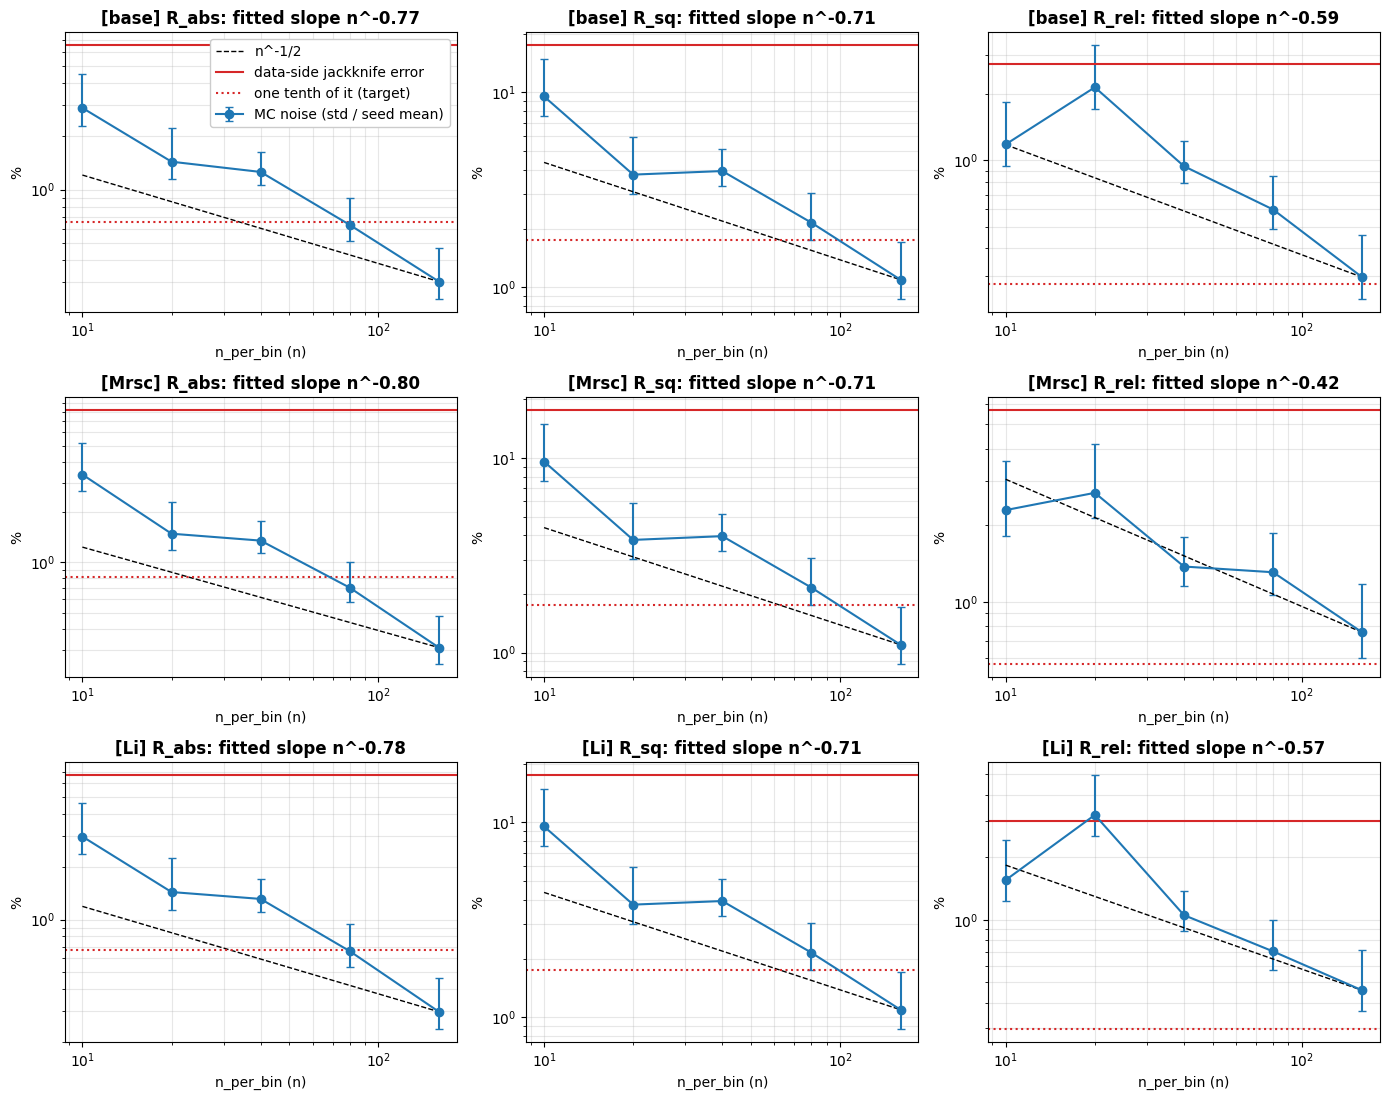

In [5]:
ns = sorted(int(g[1:]) for g in GN if re.fullmatch(r"N\d+", g) and len(GN[g]) >= 3)

rows = {k: {n: group_rel_noise(RES, GN[f"N{n}"], "R_" + k) for n in ns} for k in OBS}
big = max(ns) # data-side jackknife error of each residual: mean over the runs of the largest group
jk = {k: np.mean([jackknife_rel_error(RES[n]["R_" + k], RES[n]["R_loo"][i]) for n in GN[f"N{big}"]]) 
      for i, k in enumerate(OBS)}

for s in SETS:
    ks = [key_of(s, o) for o in OBS3]
    print(f"\n[{s:4s}] {'n':>5s} {'runs':>5s} " + " ".join(f"{('noise '+o):>14s}" for o in OBS3) + 
          "     (relative std over seeds, %; MAD-based in brackets)")
    for n in ns:
        print(f"{'':>5s} {n:5d} {rows[ks[0]][n]['n']:5d} " + 
              " ".join(f"{100*rows[k][n]['rel']:8.2f} ({100*rows[k][n]['mad_rel']:4.2f})" for k in ks))
    print(f"{'':>5s} data-side jackknife error of R (%): " + ", ".join(f"{o} {100*jk[k]:.2f}" for o, k in zip(OBS3, ks)))

fig, ax = plt.subplots(len(SETS), 3, figsize=(14, 3.7 * len(SETS)), squeeze=False)
for r, s in enumerate(SETS):
    for c, o in enumerate(OBS3):
        k, a = key_of(s, o), ax[r, c]
        x = np.array(ns)
        y = np.array([rows[k][n]["rel"] for n in ns])
        lo = np.array([rows[k][n]["rel_lo"] for n in ns])
        hi = np.array([rows[k][n]["rel_hi"] for n in ns])
        a.errorbar(x, 100 * y, yerr=100 * np.array([y - lo, hi - y]), fmt="o-", capsize=3, label="MC noise (std / seed mean)")
        
        sl = np.polyfit(np.log(x), np.log(y), 1)[0] if len(x) > 1 else np.nan

        a.plot(x, 100 * y[-1] * np.sqrt(x[-1] / x), "k--", lw=1, label="n^-1/2")
        a.axhline(100 * jk[k], color="C3", label="data-side jackknife error")
        a.axhline(10 * jk[k], color="C3", ls=":", label="one tenth of it (target)")
        a.set_xscale("log")
        a.set_yscale("log")
        a.set_xlabel("n_per_bin (n)")
        a.set_ylabel("%")
        a.set_title(f"[{s}] R_{o}: fitted slope n^{sl:.2f}", weight="bold")
        a.grid(alpha=0.3, which="both")
        if r == 0 and c == 0: a.legend(framealpha=1, loc="upper right")

plt.tight_layout()
plt.show()

## 2. How the residuals scatter over seeds

We can also look at how each seed's resdiual (after being normalized by the group mean, which is what we have in the plots above) scatter, and more importantly, how the scatter decreases as a function of $n$.

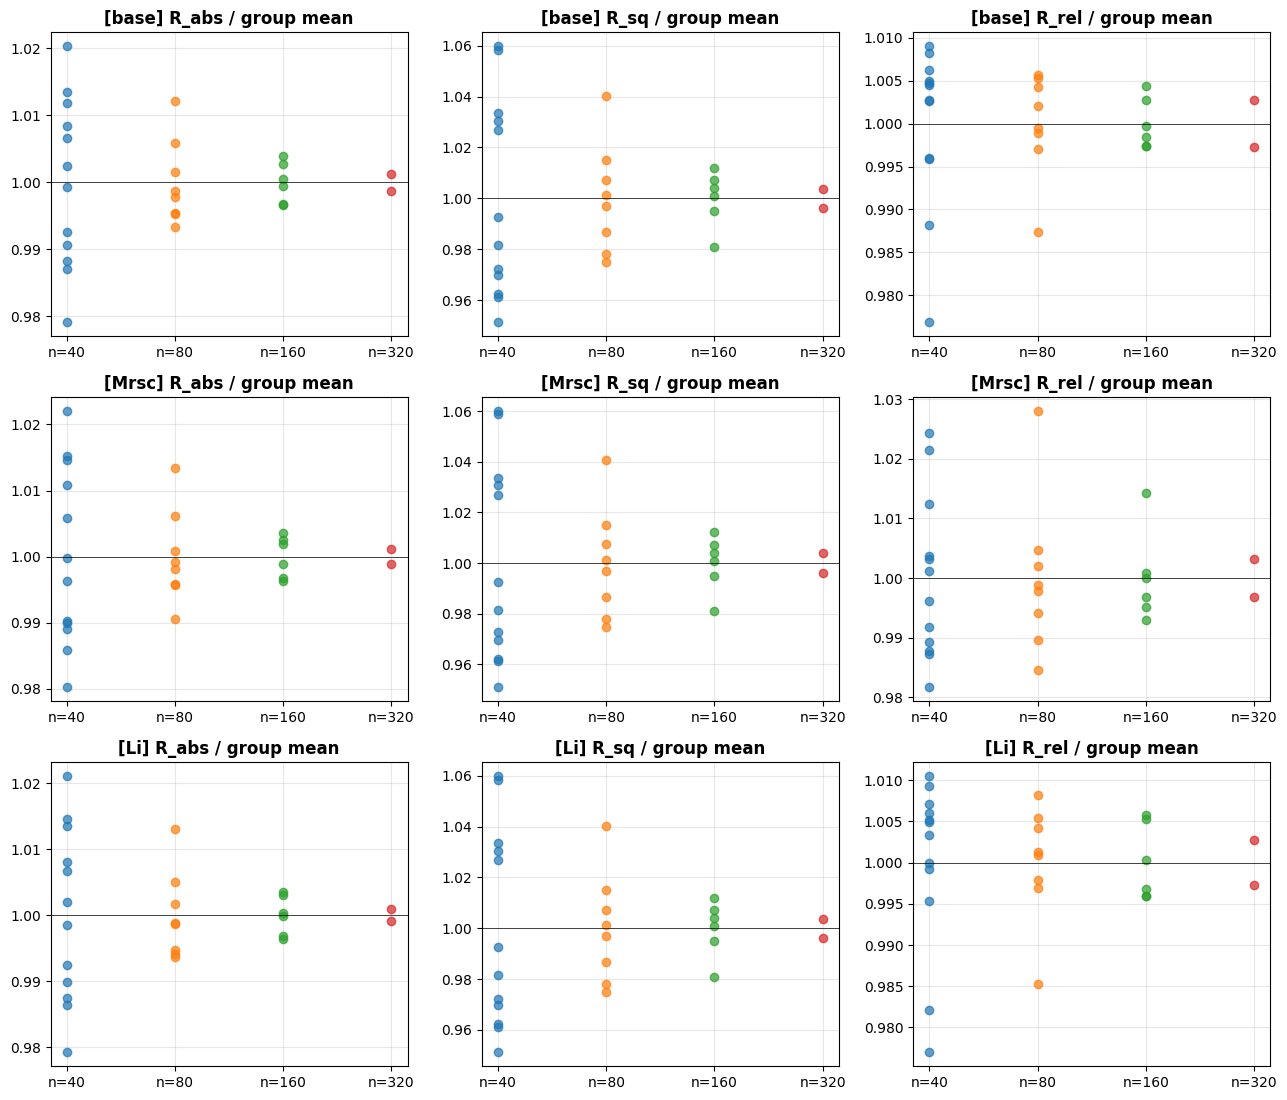

In [6]:
show = [n for n in (40, 80, 160, 320) if f"N{n}" in GN]

fig, ax = plt.subplots(len(SETS), 3, figsize=(13, 3.7 * len(SETS)), squeeze=False)

for r, s in enumerate(SETS):
    for c, o in enumerate(OBS3):
        k, a = key_of(s, o), ax[r, c]
        for j, n in enumerate(show):
            v = np.array([RES[x]["R_" + k] for x in GN[f"N{n}"]])
            a.plot(np.full(len(v), j), v / v.mean(), "o", alpha=0.7)

        a.set_xticks(range(len(show)))
        a.set_xticklabels([f"n={n}" for n in show])
        a.axhline(1, color="k", lw=0.5)
        a.set_title(f"[{s}] R_{o} / group mean", weight="bold")
        a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Azimuth-phase noise and the numerical settings

Herein, we look at how changing individual numerical settings (and also the seed of the azmiuth `Z`) affects the convergence, done for each residual we consider.

Importantly, the relative shifts are paired with the baseline run at $n$ = 40 and whatever parameter setting was default, so that the shift can be expressed in terms of $\sigma$.

Considering $\pm1\sigma$ as the threshold, we see that most numerical settings are negligible for all residual types. The two notes that must be made are that the azimuthal fidelity `factor_phi_res` behave differently for different residual types and that the kernel smoothing and `R_clump` make enormous changes, but are predictable, e.g. $R_{\rm clump}/3$ gives about $2\sigma$.

Paired relative shift of R vs N40 (%, ± standard error); z = shift / SE;  last columns: shift in units of the seed noise at n=40

[base]
setting              abs                     sq                      rel             |sh|/noise abs  |sh|/noise sq |sh|/noise rel
S_dt25       +0.00+-0.00 (z  +nan)   +0.00+-0.00 (z  +nan)   +0.00+-0.00 (z  +nan)             0.00           0.00           0.00
S_dx0025     -0.05+-0.22 (z  -0.2)   -0.02+-0.27 (z  -0.1)   -0.16+-0.33 (z  -0.5)             0.04           0.01           0.17
S_dx0100     -0.31+-0.15 (z  -2.0)   -0.23+-0.58 (z  -0.4)   -0.40+-0.09 (z  -4.2)             0.24           0.06           0.42
S_iter300    -0.06+-0.05 (z  -1.2)   -0.06+-0.04 (z  -1.4)   -0.11+-0.08 (z  -1.3)             0.04           0.02           0.12
S_nokern     +3.06+-0.05 (z +58.5)   +6.42+-0.51 (z +12.5)   +2.92+-0.12 (z +24.9)             2.43           1.63           3.10
S_phi05      -0.62+-0.61 (z  -1.0)   -0.45+-0.52 (z  -0.9)   -0.95+-0.91 (z  -1.0) 

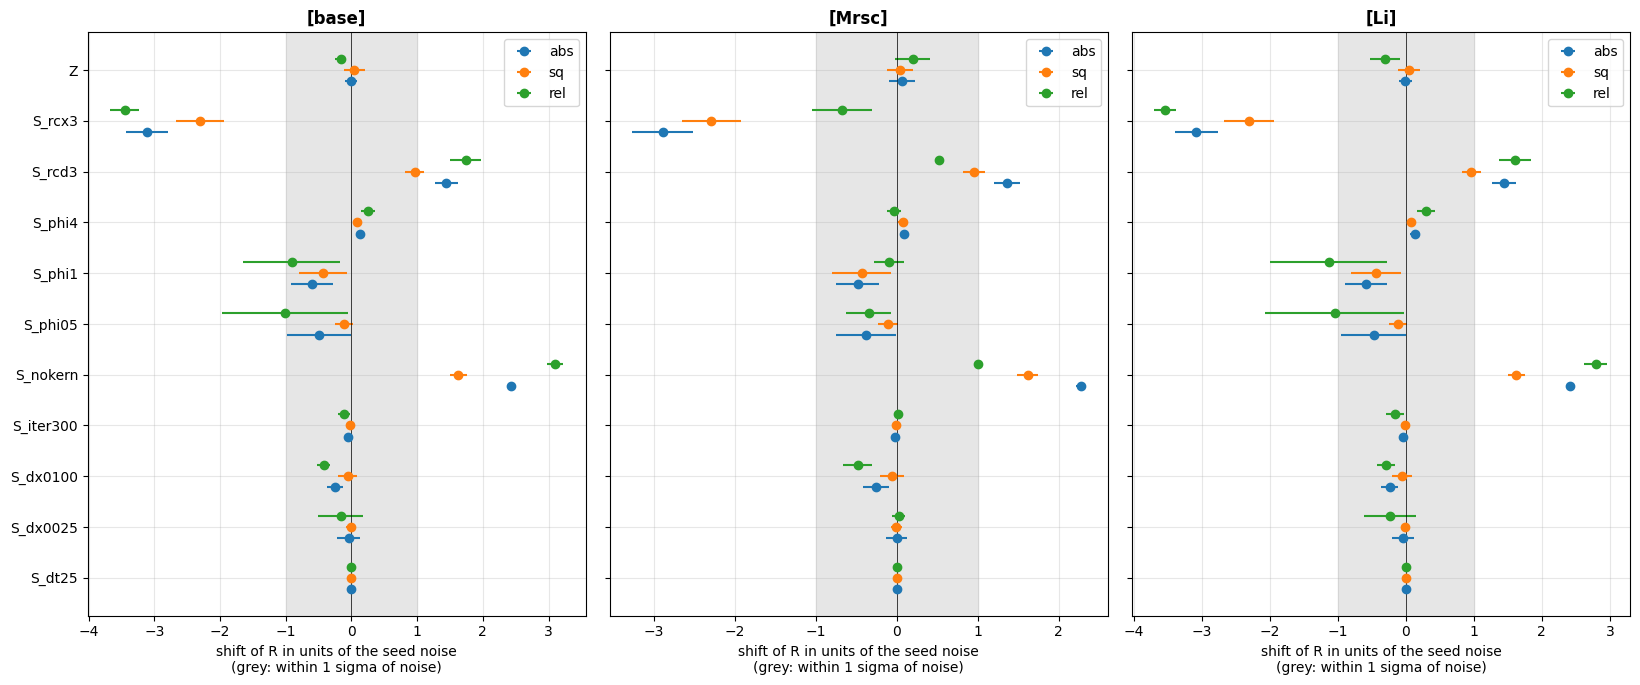

In [7]:
base = {s: nm for s, nm in G.get(f"N{N_REF}", {}).items()}
noise_ref = {k: group_rel_noise(RES, GN[f"N{N_REF}"], "R_" + k)["rel"] for k in OBS} if f"N{N_REF}" in GN else {}
tags = [g for g in sorted(G) if g == "Z" or g.startswith("S_")]
tab = {}

for g in tags:
    seeds = sorted(set(G[g]) & set(base))
    if len(seeds) < 2:
        continue
    tab[g] = {k: paired_rel_shift(RES, [base[s] for s in seeds], [G[g][s] for s in seeds], "R_" + k) for k in OBS}

print(f"Paired relative shift of R vs N{N_REF} (%, ± standard error); z = shift / SE;  last columns: shift in units of the seed noise at n={N_REF}")
for s in SETS:
    ks = [key_of(s, o) for o in OBS3]
    print(f"\n[{s}]")
    print(f"{'setting':10s} " + " ".join(f"{o:^23s}" for o in OBS3) + "   " + " ".join(f"{('|sh|/noise '+o):>14s}" for o in OBS3))
    for g, r in tab.items():
        print(f"{g:10s} " + 
              " ".join(f"{100*r[k]['mean']:+7.2f}+-{100*r[k]['se']:4.2f} (z {r[k]['z']:+5.1f})" for k in ks) + "   " + 
              " ".join(f"{abs(r[k]['mean'])/noise_ref[k]:14.2f}" for k in ks))

fig, axs = plt.subplots(1, len(SETS), figsize=(5.5 * len(SETS), 0.45 * len(tab) + 2), sharey=True, squeeze=False)
ypos = np.arange(len(tab))
for ax, s in zip(axs[0], SETS):
    for j, o in enumerate(OBS3):
        k = key_of(s, o)
        ax.errorbar([tab[g][k]["mean"] / noise_ref[k] for g in tab], 
                    ypos + 0.22 * (j - 1), xerr=[tab[g][k]["se"] / noise_ref[k] for g in tab], fmt="o", label=o)

    ax.axvline(0, color="k", lw=0.5)
    ax.axvspan(-1, 1, color="0.9", zorder=0)
    ax.set_yticks(ypos)
    ax.set_yticklabels(list(tab))
    ax.set_title(f"[{s}]", weight="bold")
    ax.set_xlabel("shift of R in units of the seed noise\n(grey: within 1 sigma of noise)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. The dR scan (radial discretisation) and the old dR = 0.5 setting

We also check whether a choice for `dR`, which is inherently tied to `n_per_bin`, change the relative shift of the group. The `dR=0.25` was a practical choice, but it seems that it wasn't a particularly bad one.

In [8]:
rg = [g for g in sorted(GN) if re.fullmatch(r"R\d{3}", g) or g == "Rold"]

print(f"relative shift of the group mean R vs N{N_REF} (dR = 0.25), % ± SE (unpaired: the random draws differ)")
for g in rg:
    print(f"  {g:6s} ({len(GN[g])} runs):")
    for s in SETS:
        row = []
        for o in OBS3:
            k = key_of(s, o)
            a = np.array([RES[x]["R_" + k] for x in GN[f"N{N_REF}"]])
            b = np.array([RES[x]["R_" + k] for x in GN[g]])
            se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)) / a.mean() if len(b) > 1 else np.nan
            row.append(f"{o} {100*(b.mean()/a.mean()-1):+6.2f}+-{100*se:4.2f}")

        print(f"      [{s:4s}] " + "   ".join(row))

relative shift of the group mean R vs N40 (dR = 0.25), % ± SE (unpaired: the random draws differ)
  R010   (3 runs):
      [base] abs  -0.22+-0.57   sq  +0.31+-2.45   rel  -0.77+-0.35
      [Mrsc] abs  -0.14+-0.76   sq  +0.32+-2.47   rel  -0.65+-0.69
      [Li  ] abs  -0.15+-0.62   sq  +0.31+-2.45   rel  -0.77+-0.60
  R050   (3 runs):
      [base] abs  -0.24+-0.47   sq  -0.99+-1.92   rel  -0.18+-0.43
      [Mrsc] abs  -0.40+-0.47   sq  -1.00+-1.93   rel  -1.47+-0.41
      [Li  ] abs  -0.28+-0.49   sq  -0.99+-1.92   rel  +0.11+-0.66
  R100   (3 runs):
      [base] abs  -0.37+-1.88   sq  -3.34+-4.66   rel  +0.97+-0.94
      [Mrsc] abs  -0.83+-2.13   sq  -3.39+-4.69   rel  -0.09+-0.55
      [Li  ] abs  -0.42+-1.92   sq  -3.34+-4.67   rel  +1.13+-1.11
  Rold   (2 runs):
      [base] abs  -0.02+-0.37   sq  +0.87+-1.54   rel  -0.80+-0.32
      [Mrsc] abs  +0.24+-0.40   sq  +0.89+-1.55   rel  -0.19+-0.72
      [Li  ] abs  +0.18+-0.40   sq  +0.87+-1.55   rel  -1.04+-0.31


## 5. Sensitivity to hv0 and the noise per evaluation in km/s of hv0

We finally consider how sensitive each residual is to a change in `hv0` and to the noise (in km/s) per evaluation. For a grid search, the noise of the residual should not be larger than the grid step. So, for a residual that performs bad in this, it cannot be used in grid search.

      R     n  seeds    d ln R / d hv0 [%/(km/s)]  noise per eval [km/s]  with CRN [km/s]  step significance (z)
    abs    40      8                       -0.134                    9.4              4.7                   -3.0
    abs    80      8                       -0.061                   10.3              7.9                   -1.8
    abs   160      6                       -0.132                    2.3              4.0                   -3.0
     sq    40      8                       -0.722                    5.5              2.0                   -7.0
     sq    80      8                       -0.659                    3.3              1.6                   -8.9
     sq   160      6                       -0.686                    1.6              1.9                   -6.5
    rel    40      8                       -0.066                   14.2              8.4                   -1.7
    rel    80      8                        0.076                    7.9             10.4       

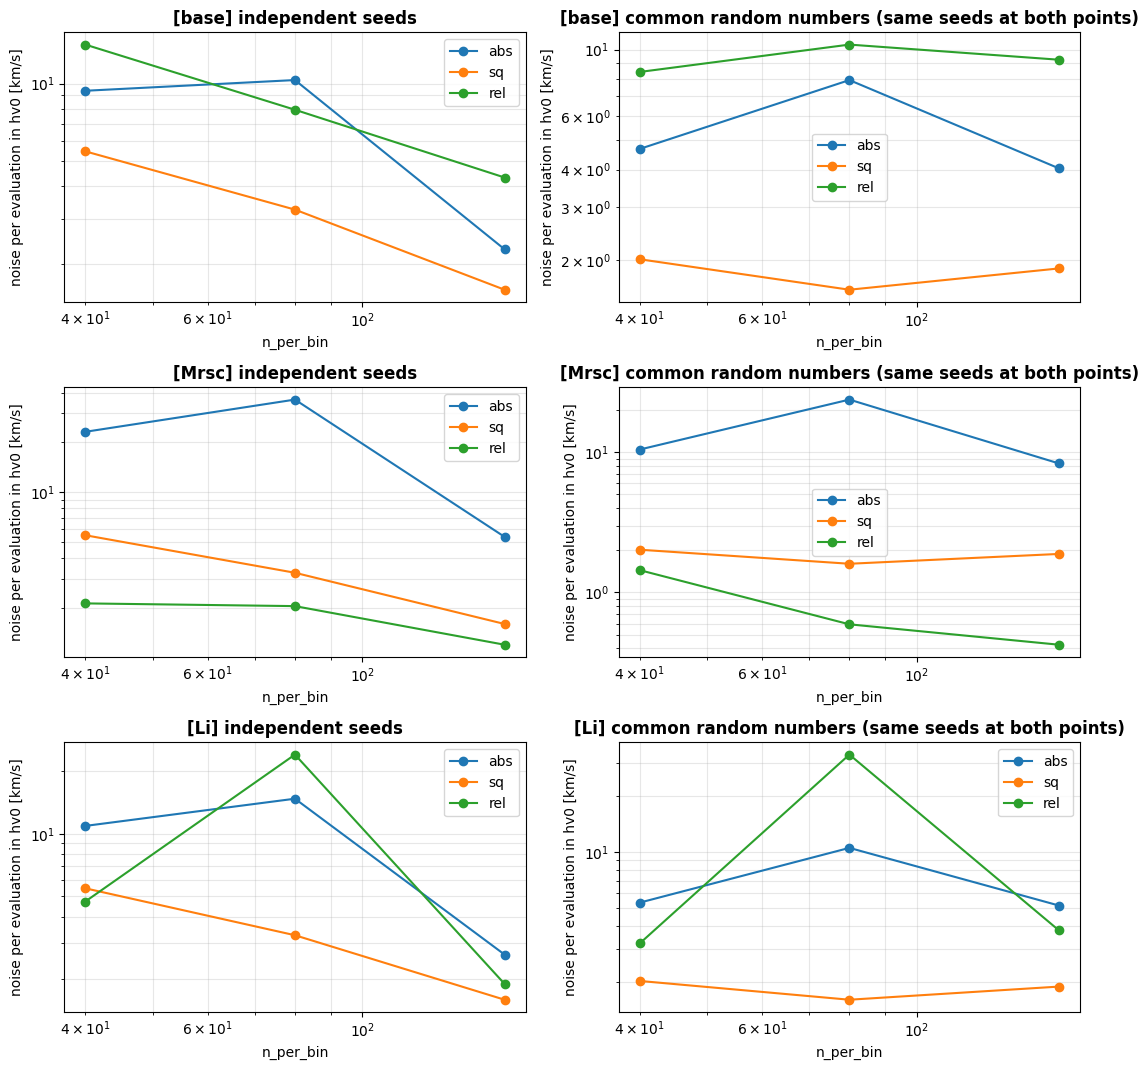

In [9]:
sens = {}
for n in (10, 20, 40, 80, 160, 320):
    if f"N{n}" in G and f"D{n}" in G:
        seeds = sorted(set(G[f"N{n}"]) & set(G[f"D{n}"]))
        if len(seeds) < 3:
            continue

        for k in OBS:
            d = np.array([(RES[G[f"D{n}"][s]]["R_" + k] - RES[G[f"N{n}"][s]]["R_" + k]) / RES[G[f"N{n}"][s]]["R_" + k] 
                          for s in seeds])
            
            noise_abs = group_rel_noise(RES, GN[f"N{n}"], "R_" + k)["rel"]
            slope = d.mean() / HV_STEP                                         # relative change per km/s
            sens[(k, n)] = dict(slope=slope, 
                                n=len(seeds), 
                                jitter_abs=noise_abs / abs(slope), 
                                jitter_crn=d.std(ddof=1) / abs(d.mean()) * HV_STEP, 
                                step_z=d.mean() / (d.std(ddof=1) / np.sqrt(len(d))))

print(f"{'R':>7s} {'n':>5s} {'seeds':>6s} {'d ln R / d hv0 [%/(km/s)]':>28s} "
      f"{'noise per eval [km/s]':>22s} {'with CRN [km/s]':>16s} {'step significance (z)':>22s}")

order = {k: i for i, k in enumerate(OBS)}
for (k, n), r in sorted(sens.items(), key=lambda t: (order[t[0][0]], t[0][1])):
    print(f"{k:>7s} {n:5d} {r['n']:6d} {100*r['slope']:28.3f} {r['jitter_abs']:22.1f} "
          f"{r['jitter_crn']:16.1f} {r['step_z']:22.1f}")
    

fig, ax = plt.subplots(len(SETS), 2, figsize=(11, 3.6 * len(SETS)), squeeze=False)
for r, s in enumerate(SETS):
    for o in OBS3:
        k = key_of(s, o)
        nn = sorted(n for (kk, n) in sens if kk == k)
        ax[r, 0].plot(nn, [sens[(k, n)]["jitter_abs"] for n in nn], "o-", label=o)
        ax[r, 1].plot(nn, [sens[(k, n)]["jitter_crn"] for n in nn], "o-", label=o)

    for a, t in zip(ax[r], ("independent seeds", "common random numbers (same seeds at both points)")):
        a.set_xscale("log")
        a.set_yscale("log")
        a.set_xlabel("n_per_bin")
        a.set_ylabel("noise per evaluation in hv0 [km/s]")
        a.set_title(f"[{s}] {t}", weight="bold")
        a.grid(alpha=0.3, which="both")
        a.legend()

plt.tight_layout()
plt.show()

## Performance Table

We finally arrive at a performance table to see which observable residual performs well across our tests. I have marked residuals that perform better than a threshold with asterisks

A residual is usable for a grid search when its noise is well below its jackknife error (the current ratio is 0.2) AND the noise per evaluation in hv0 is small compared with the grid step (the current sensitivity limit is 0.5% and noise is 2.0 - less than half the grid step). It is also beneficial is it is not dominated by the top 15 (the current limit is 10%).

*From out tentative results, it seems like there isn't one good choise, though `abs_L` and `rel_L` are quite appealing.*

In [10]:
def pick(n_list, k):
    for n in n_list:
        if (k, n) in sens: return n
    return None

print(f"{'residual':>9s} | rank | {'noise @ n=40 [%]':>16s} {'data jk [%]':>12s} {'noise/err_jk':>13s}  | "
      f"{'sensi.[%/(km/s)]':>16s}  {'noise in hv0 [km/s]':>20s}  | {'N_eff vox':>9s} {'top 1% ':>8s}")

for k in (OBS if jk else ()):
    n40 = group_rel_noise(RES, GN["N40"], "R_" + k)["rel"] if "N40" in GN else np.nan
    nn = pick((160, 80, 40), k)
    neff = np.mean([RES[x]["neff_" + k] for x in GN.get("N40", [])]) if "N40" in GN else np.nan
    top1 = np.mean([RES[x]["top1pct_" + k] for x in GN.get("N40", [])]) if "N40" in GN else np.nan

    star_1 = "*" if n40/jk[k] < (thres_1 := 0.25) else " "
    star_2 = "*" if np.abs(100*sens[(k, nn)]['slope']) < (thres_2 := 0.5) else " "
    star_3 = "*" if sens[(k, nn)]['jitter_abs'] < (thres_3 := 2.0) else " "
    star_4 = "*" if 100*top1 < (thres_4 := 10) else " "

    print(f"{k:>9s} | {star_1}{star_2}{star_3}{star_4} | {100*n40:16.2f} {100*jk[k]:12.2f} {n40/jk[k]:13.2f}{star_1} | " + 
          (f"{100*sens[(k, nn)]['slope']:16.3f}{star_2} {sens[(k, nn)]['jitter_abs']:20.1f}" if nn else f"{'-':>16s} {'-':>20s}") + 
          f"{star_3} | {neff:9.0f} {100*top1:6.1f}%{star_4}")

print()
for s in SETS:
    if f"n_sel_{s}" in RES[GN["N40"][0]]:
        print(f"set {s}: voxels selected, mean over the N40 runs: " 
              f"{np.mean([RES[x]['n_sel_' + s] for x in GN['N40']]):.0f} of {RES[GN['N40'][0]]['n_valid']}")

print(f"* means (1) noise/err_jk < {thres_1}, (2) sensi.y < {thres_2}%, (3) hv0 noise < {thres_3}, or (4) top1% < {thres_4}%.")

 residual | rank | noise @ n=40 [%]  data jk [%]  noise/err_jk  | sensi.[%/(km/s)]   noise in hv0 [km/s]  | N_eff vox  top 1% 
      abs | **   |             1.26         6.57          0.19* |           -0.132*                  2.3  |     12012   27.7% 
       sq | * *  |             3.95        17.49          0.23* |           -0.686                   1.6* |      1306   71.4% 
      rel |  * * |             0.94         2.74          0.34  |           -0.068*                  4.3  |     69308    6.4%*
 abs_Mrsc | **   |             1.35         8.18          0.16* |           -0.057*                  5.4  |      7735   34.7% 
  sq_Mrsc | * *  |             3.97        17.64          0.22* |           -0.685                   1.6* |      1286   71.9% 
 rel_Mrsc | * *  |             1.38         5.68          0.24* |            0.632                   1.2* |     17542   14.5% 
   abs_Li | **   |             1.31         6.69          0.20* |           -0.113*                  2.6  |    